# 01 Build the volatility-managed portfolios

Builds volatility-managed **cyclical** portfolios (XLB, XLE, XLF, XLI, XLY) from every model in
`SELECTED` (`models/research_config.py`), following Moreira & Muir (2017), under both
specifications of the reference variance σ̄², and saves them to `results/portfolios/`. There is no
evaluation here: `p2_portfolio_eval.ipynb` and `p3_forecast_vs_portfolio.ipynb` read the saved
portfolios.

1. **Variance forecast**: σ̂²ᵢ,ₜ₊₁ = `fc_level`, the forecast of month t+1's realised variance made
   at the end of month t (log-normal corrected for the log models).
2. **Base weight**: wᵢ,ₜ = min(σ̄²ᵢ / σ̂²ᵢ,ₜ₊₁, k), k = 2, with σ̄²ᵢ either
   - **fixed** (main): the ETF's mean monthly realised variance over the training window
     (2003-03 to 2008-02), or
   - **expanding** (robustness): σ̄²ᵢ,ₜ, the mean from 2003-03 through month t.
3. **Per-ETF positions**: positionᵢ,ₜ₊₁ = wᵢ,ₜ (rᵢ,ₜ₊₁ − rfₜ₊₁).
4. **Equal-weighted aggregation**: g_{t+1} = (1/N) Σᵢ positionᵢ,ₜ₊₁. Buy-and-hold uses wᵢ,ₜ = 1.
5. **Bucket-level rescale**: c = σ(BH) / σ(g) over the out-of-sample period, f^σ = c · g.

Two benchmarks are built alongside the models:

- **Buy-and-hold (BH)**, the 1/N cyclical bucket with w = 1: does volatility timing work at all?
- **`hist_rw`**, the historical-volatility benchmark σ̂²ᵢ,ₜ₊₁ = RVᵢ,ₜ
  (`models/forecasting/build_hist_rw.py`). This is the Moreira & Muir portfolio, so beating it
  means a forecast adds something beyond the simplest volatility timing.

Under the expanding specification it also builds the **re-levering control**, with weight
min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2) and no forecast.

## Setup

In [1]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



from research_config import SELECTED, TICKERS, TRAIN_START, TRAIN_MONTHS, BENCHMARK, BLOCKS
from portfolio.config import FORECAST_COL, K_CAP, SPECS, MAIN_SPEC
from utils.portfolio_utils import (
    CONTROL, FORECAST_FILES, PORTFOLIO_DIR,
    load_monthly_returns, training_window, load_forecast_files, check_alignment, forecast_wide,
    resolve_blocks, build_portfolio, sigma2_bar_fixed, sigma2_bar_expanding, build_control,
    pct_capped, pct_capped_pooled, save_portfolios, load_portfolios,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

### Selected models and comparison pairs

The models come from `SELECTED` and the comparison pairs from `BLOCKS`, both in
`research_config.py`. A selected model that is not in its forecast file yet is skipped with a notice, and so is every pair that uses it. It is included
automatically once its forecasts are added to `models/forecasting/forecasts/`.

In [2]:
forecasts_raw, available = load_forecast_files(SELECTED)
for family, df in forecasts_raw.items():
    print(f"{family} ({FORECAST_FILES[family]}): variants in file {sorted(df['model'].unique())}")

VARIANTS = [v for variants in available.values() for v in variants]
assert BENCHMARK in VARIANTS, f"the benchmark {BENCHMARK} must be built"

pairs, skipped = resolve_blocks(BLOCKS, VARIANTS)
print("\nBuilding portfolios for:", VARIANTS)
print("Specifications:", SPECS, f"(main: {MAIN_SPEC})")
print(f"\n{len(pairs)} comparison pairs will be tested; {len(skipped)} are skipped:")
skipped

Historical (hist_rw_forecasts.csv): variants in file ['hist_rw']
Garch (garch_forecasts.csv): variants in file ['garch', 'garch_midas_baa10y']
Elastic Net (en_forecasts.csv): variants in file ['en_full_macro', 'en_no_macro', 'en_no_vix', 'en_vix_only']
XGBoost (xgb_forecasts_expanding_tidy.csv): variants in file ['ols_har_no_macro', 'xgb_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only']

Building portfolios for: ['hist_rw', 'garch', 'garch_midas_baa10y', 'en_no_macro', 'en_no_vix', 'en_vix_only', 'en_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only', 'xgb_full_macro']
Specifications: ['fixed', 'expanding'] (main: fixed)

14 comparison pairs will be tested; 0 are skipped:


,block,a,b,isolates,missing
pair,,,,,


### Monthly excess returns and realised variance

Daily returns are compounded to monthly returns and the daily risk-free rate to a monthly rate,
so rᵢ,ₜ₊₁ − rfₜ₊₁ is the monthly excess return. Monthly realised variance is the sum of squared
daily returns, the same definition as `actual_RV` in the forecast files.

In [3]:
xret_monthly, rv_monthly = load_monthly_returns(TICKERS)
print("Monthly sample:", xret_monthly.index.min().date(), "to", xret_monthly.index.max().date(),
      f"({len(xret_monthly)} months)")

Monthly sample: 2003-01-31 to 2025-12-31 (276 months)


### Training and out-of-sample windows

The training window is the 60 months from 2003-03 to 2008-02. The out-of-sample (holding) period
is every month after it, from 2008-03 to the end of the data.

In [4]:
train_idx, oos_start = training_window(TRAIN_START, TRAIN_MONTHS)
assert train_idx.min() in rv_monthly.index, "price data does not cover the training window"

print(f"Training window: {train_idx.min():%Y-%m} to {train_idx.max():%Y-%m} ({len(train_idx)} months)")
print(f"Out-of-sample starts: {oos_start:%Y-%m}")

Training window: 2003-03 to 2008-02 (60 months)
Out-of-sample starts: 2008-03


## Step 1: Variance forecasts

**Date alignment.** In the forecast files, the row dated t holds the forecast made at the end of
month t for month t+1: its `actual_RV` equals the realised variance of month **t+1** in the price
data (checked below). Each forecast is therefore re-indexed to its holding month t+1, so the
weight for a month uses only information available before that month began. The check covers
`hist_rw` too: its forecast for t+1 is month t's realised variance, which is known at the end of
month t.

In [5]:
align = pd.DataFrame({f: check_alignment(df, available[f][0], rv_monthly)
                      for f, df in forecasts_raw.items()}).T
print("Correlation of actual_RV with price-data RV:")
print(align)
assert (align["next month (t+1)"] > 0.999).all(), "forecast dates are not origin-dated as expected"
for family, frame in forecasts_raw.items():
    for variant in available[family]:
        actual = forecast_wide(frame, variant, "actual_RV", TICKERS)
        expected = rv_monthly.reindex(index=actual.index, columns=TICKERS)
        if not np.allclose(actual, expected, rtol=1e-10, atol=1e-12):
            raise ValueError(f"{variant}: forecast actual_RV differs from excess-return RV; rebuild forecasts")

Correlation of actual_RV with price-data RV:
             same month (t)  next month (t+1)
Historical           0.5818            1.0000
Garch                0.5818            1.0000
Elastic Net          0.5818            1.0000
XGBoost              0.5817            1.0000


In [6]:
sigma2_hat_all = {v: forecast_wide(forecasts_raw[f], v, FORECAST_COL, TICKERS)
                  for f, variants in available.items() for v in variants}

coverage = pd.DataFrame({
    v: {"first_holding": s2.index.min().date(), "last_holding": s2.index.max().date(),
        "months_before_oos (dropped)": (s2.index < oos_start).sum(),
        "oos_months": (s2.index >= oos_start).sum()}
    for v, s2 in sigma2_hat_all.items()
}).T
coverage

,first_holding,last_holding,months_before_oos (dropped),oos_months
hist_rw,2008-03-31,2025-12-31,0,214
garch,2008-03-31,2025-12-31,0,214
garch_midas_baa10y,2008-03-31,2025-12-31,0,214
en_no_macro,2008-03-31,2025-12-31,0,214
en_no_vix,2008-03-31,2025-12-31,0,214
en_vix_only,2008-03-31,2025-12-31,0,214
en_full_macro,2008-03-31,2025-12-31,0,214
xgb_no_macro,2008-02-29,2025-12-31,1,214
xgb_no_vix,2008-02-29,2025-12-31,1,214
xgb_vix_only,2008-02-29,2025-12-31,1,214


Every model is evaluated on the same months: on or after the out-of-sample start, with returns and
a forecast from every selected model. A model whose forecasts start later would shorten the window
for all of them, so the cell stops if the common window does not start at the out-of-sample start.

In [7]:
oos_idx = xret_monthly.index[xret_monthly.index >= oos_start]
for s2 in sigma2_hat_all.values():
    oos_idx = oos_idx.intersection(s2.dropna().index)

late = [v for v, s2 in sigma2_hat_all.items() if s2.dropna().index.min() > oos_start]
assert oos_idx.min() == oos_start, (
    f"common window starts {oos_idx.min():%Y-%m}, not {oos_start:%Y-%m}; "
    f"models starting later: {late}. Remove them from SELECTED in research_config.py.")

sigma2_hat = {v: s2.loc[oos_idx] for v, s2 in sigma2_hat_all.items()}
xret_oos = xret_monthly.loc[oos_idx, TICKERS]

print(f"Out-of-sample period: {oos_idx.min():%Y-%m} to {oos_idx.max():%Y-%m} ({len(oos_idx)} months)")
assert not xret_oos.isna().any().any()

Out-of-sample period: 2008-03 to 2025-12 (214 months)


## Step 2: The reference variance σ̄², two specifications

- **Fixed** (main specification): σ̄²ᵢ is the mean monthly realised variance of ETF i over the
  training window (2003-03 to 2008-02). It is known at the first forecast date and is the same in
  every month and for every model. The only thing that moves the weights from month to month is
  the forecast σ̂²ᵢ,ₜ₊₁, so comparing managed portfolios across models is a direct test of forecast
  skill.
- **Expanding** (robustness): for holding month t+1, σ̄²ᵢ,ₜ is the mean from 2003-03 through month
  t. It is also known in real time and shared by every model, but it moves over time, so the
  weights also pick up a re-levering effect that has nothing to do with the forecast.

In the first out-of-sample month (2008-03) the expanding mean covers exactly the training window,
so the two specifications start from the same value.

In [8]:
sigma2_bar = {
    "fixed": sigma2_bar_fixed(rv_monthly[TICKERS], train_idx),
    "expanding": sigma2_bar_expanding(rv_monthly[TICKERS], TRAIN_START, oos_idx),
}
assert np.allclose(sigma2_bar["expanding"].iloc[0], sigma2_bar["fixed"]), \
    "expanding sigma2_bar should equal the training mean in the first out-of-sample month"

pd.DataFrame({
    "fixed": sigma2_bar["fixed"],
    f"expanding, {oos_idx[0]:%Y-%m}": sigma2_bar["expanding"].iloc[0],
    f"expanding, {oos_idx[-1]:%Y-%m}": sigma2_bar["expanding"].iloc[-1],
}).T

,XLB,XLE,XLF,XLI,XLY
fixed,0.0030,0.0043,0.0026,0.0017,0.0020
"expanding, 2008-03",0.0030,0.0043,0.0026,0.0017,0.0020
"expanding, 2025-12",0.0044,0.0070,0.0065,0.0035,0.0039


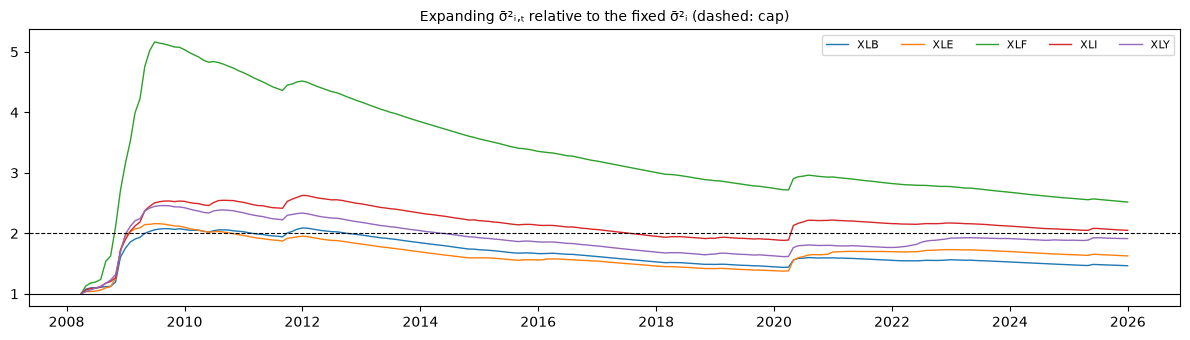

In [9]:
# Expanding / fixed: the control's weight before the cap. It starts at 1 and rises after crises.
fig, ax = plt.subplots(figsize=(12, 3.5))
ratio = sigma2_bar["expanding"] / sigma2_bar["fixed"]
for t in TICKERS:
    ax.plot(ratio.index, ratio[t], linewidth=1, label=t)
ax.axhline(1, color="black", linewidth=0.8)
ax.axhline(K_CAP, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Expanding σ̄²ᵢ,ₜ relative to the fixed σ̄²ᵢ (dashed: cap)", fontsize=10)
ax.legend(ncol=5, fontsize=8)
fig.tight_layout()
plt.show()

## Steps 3–5: Portfolio construction (every model, both specifications)

For one model's forecasts and one σ̄², `build_portfolio`:

1. computes the base weights wᵢ,ₜ = min(σ̄²ᵢ / σ̂²ᵢ,ₜ₊₁, k);
2. forms the per-ETF positions wᵢ,ₜ (rᵢ,ₜ₊₁ − rfₜ₊₁);
3. equal-weights them into the cyclical bucket, g_{t+1} = (1/N) Σᵢ positionᵢ,ₜ₊₁;
4. rescales by c = σ(BH) / σ(g), both over the out-of-sample period, so the managed bucket has
   the same volatility as buy-and-hold.

c is one constant applied after aggregation and the cap, so it leaves the Sharpe ratio, the
Ledoit-Wolf test and the alpha t-statistic unchanged. It sets the level of the alpha, volatility,
drawdown and turnover, which are therefore reported at matched out-of-sample volatility.

**Re-levering control** (expanding specification only). Under the expanding reference, a managed
portfolio's returns mix the re-levering that comes from σ̄²ᵢ,ₜ rising after crises and the timing
that comes from the forecast. The control captures only the first: the same weight formula, cap
and rescale, with the fixed reference in place of the forecast,

w^ctrl_{i,t} = min(σ̄²ᵢ,ₜ / σ̄²ᵢ,fixed, 2).

It starts at 1 and rises only when the expanding mean rises. Under the fixed reference it would be
identically buy-and-hold, so it is not built there.

In [10]:
portfolios = {spec: {v: build_portfolio(s2, xret_oos, sigma2_bar[spec], K_CAP)
                     for v, s2 in sigma2_hat.items()}
              for spec in SPECS}
portfolios["expanding"][CONTROL] = build_control(sigma2_bar["expanding"], sigma2_bar["fixed"],
                                                 xret_oos, K_CAP)

assert np.allclose(portfolios["expanding"][CONTROL]["weights_base"].iloc[0], 1)
pd.DataFrame({spec: {m: r["c"] for m, r in res.items()} for spec, res in portfolios.items()}) \
    .rename_axis("c")

,fixed,expanding
c,,
hist_rw,1.1741,0.8272
garch,1.3801,0.8525
garch_midas_baa10y,1.3734,0.8484
en_no_macro,1.4540,0.9002
en_no_vix,1.4524,0.8864
en_vix_only,1.4837,0.8876
en_full_macro,1.4994,0.9133
xgb_no_macro,1.4792,0.8690
xgb_no_vix,1.5024,0.8682


### Weight diagnostics

Per specification, model and ETF: σ̄²ᵢ (its out-of-sample mean under the expanding
specification) against the mean forecast, the distribution of the base weight wᵢ,ₜ, and the share
of months in which the cap binds. The second table pools the ETFs: the share of ETF-months at the
cap, per model and specification.

In [11]:
weight_diag = pd.concat({
    spec: pd.concat({
        m: pd.DataFrame({
            "sigma2_bar": sigma2_bar[spec].mean() if spec == "expanding" else sigma2_bar[spec],
            "mean_sigma2_hat": sigma2_hat[m].mean() if m in sigma2_hat else np.nan,
            "mean_weight": res["weights_base"].mean(),
            "min_weight": res["weights_base"].min(),
            "max_weight": res["weights_base"].max(),
            "pct_months_capped": pct_capped(res["weights_base"], K_CAP),
        })
        for m, res in portfolios[spec].items()
    })
    for spec in SPECS
}, names=["spec", "model", "ETF"])
weight_diag

sigma2_bar  mean_sigma2_hat  mean_weight  min_weight  max_weight  pct_months_capped
spec      model   ETF                                                                                     
fixed     hist_rw XLB      0.0030           0.0048       1.2277      0.0343      2.0000            23.8318
                  XLE      0.0043           0.0078       1.1819      0.0267      2.0000            24.7664
                  XLF      0.0026           0.0076       1.1744      0.0230      2.0000            28.0374
                  XLI      0.0017           0.0040       0.9752      0.0195      2.0000             9.8131
                  XLY      0.0020           0.0044       1.0372      0.0315      2.0000            20.0935
...                           ...              ...          ...         ...         ...                ...
expanding control XLB      0.0050              NaN       1.6668      1.0000      2.0000            15.8879
                  XLE      0.0072              NaN       1.6639      1.0000      2.0000             9.8131
                  XLF      0.0086              NaN       1.9762      1.0000      2.0000            96.7290
                  XLI      0.0037              NaN       1.9546      1.0000      2.0000            79.9065
                  XLY      0.0039              NaN       1.8449      1.0000      2.0000            29.9065

[115 rows x 6 columns]

In [12]:
pct_at_cap = pd.DataFrame({spec: {m: pct_capped_pooled(r["weights_base"], K_CAP) for m, r in res.items()}
                           for spec, res in portfolios.items()})
pct_at_cap.rename_axis("% of ETF-months at the cap")

,fixed,expanding
% of ETF-months at the cap,,
hist_rw,21.3084,54.0187
garch,4.3925,45.5140
garch_midas_baa10y,4.2991,44.2991
en_no_macro,5.3271,36.7290
en_no_vix,4.7664,33.2710
en_vix_only,2.9907,38.4112
en_full_macro,3.2710,36.0748
xgb_no_macro,1.0280,33.2710
xgb_no_vix,0.4673,29.5327


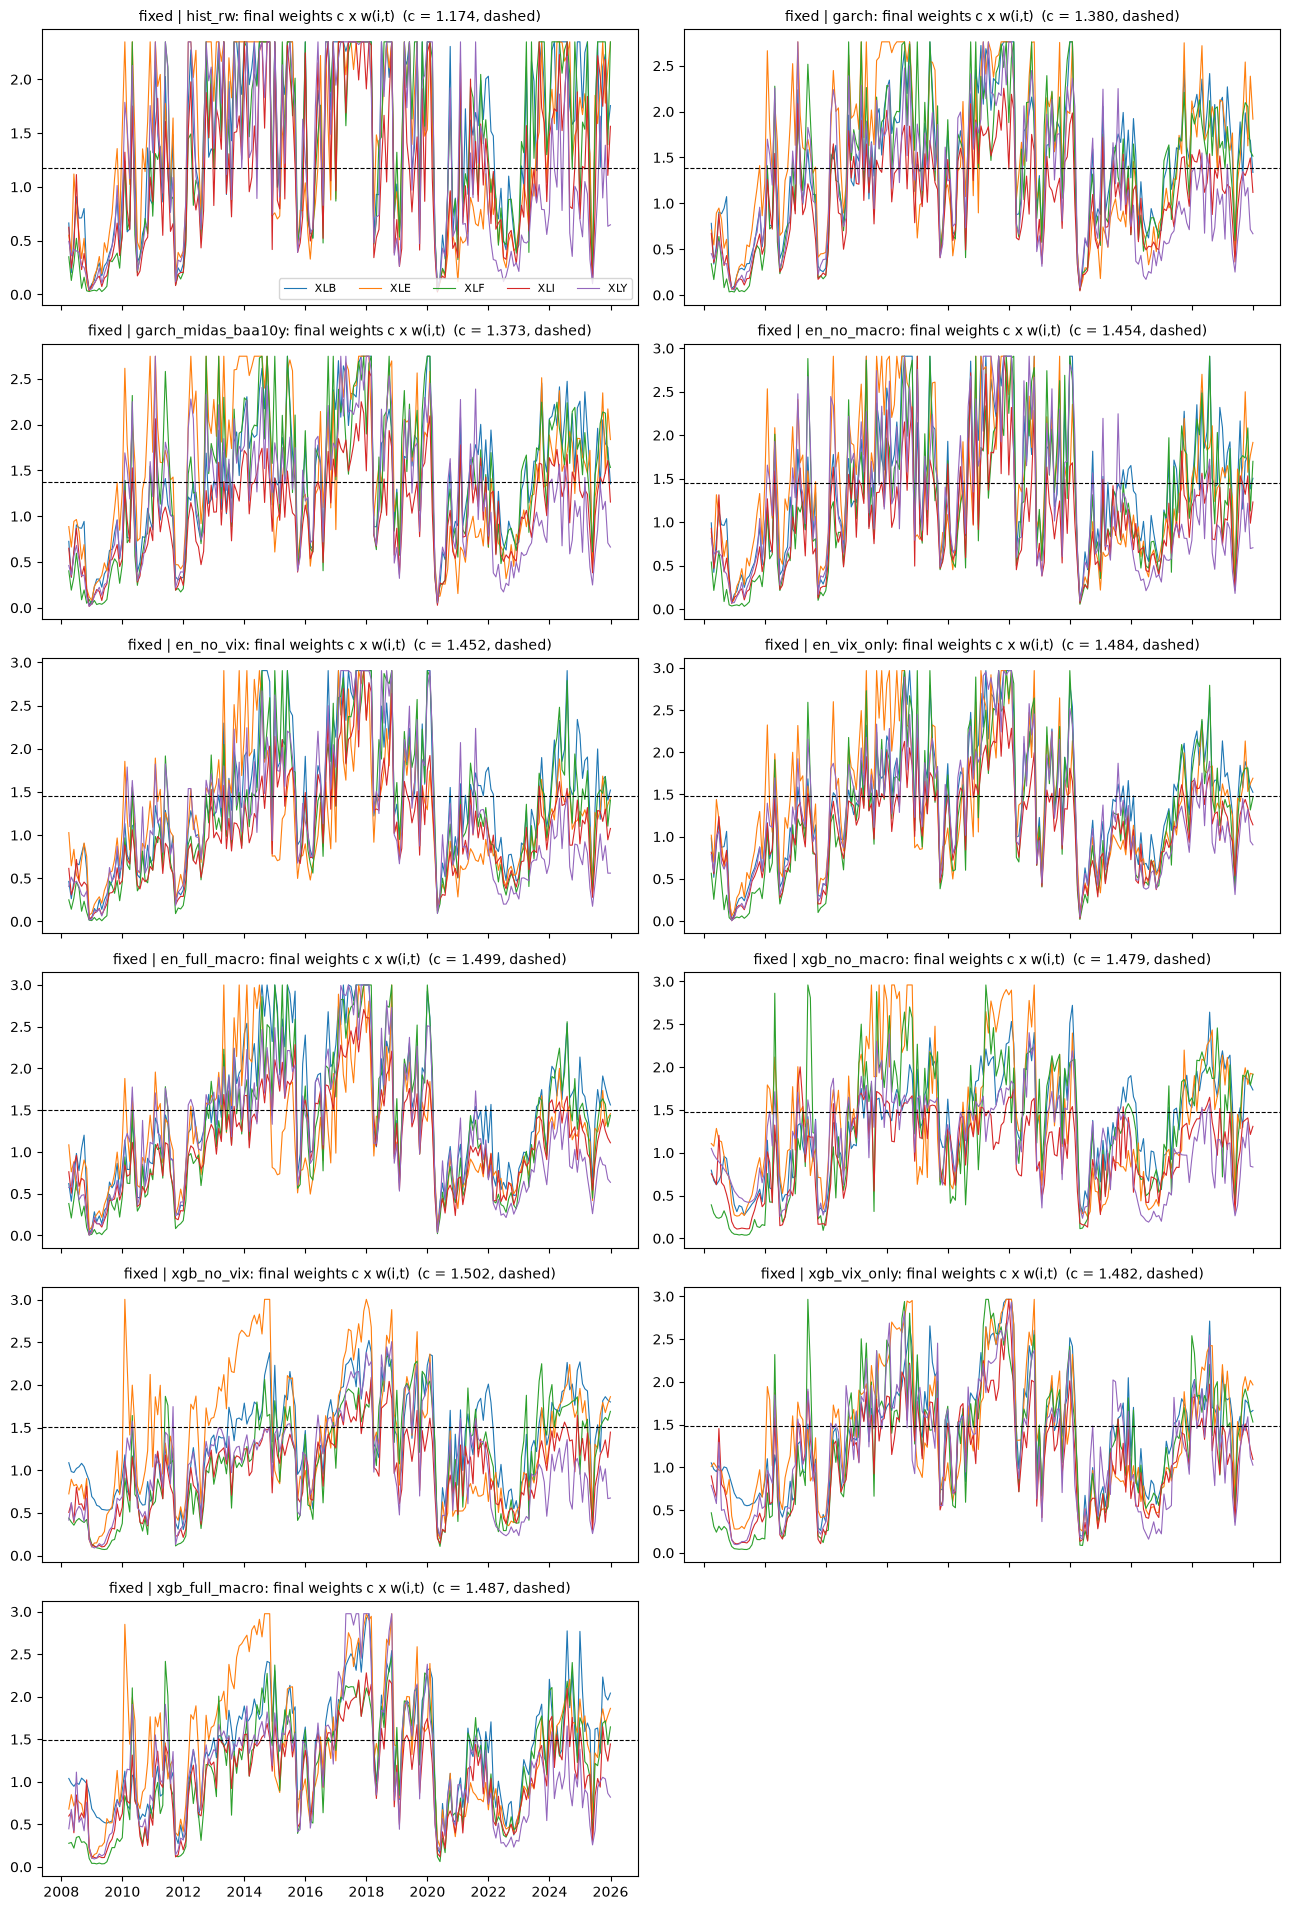

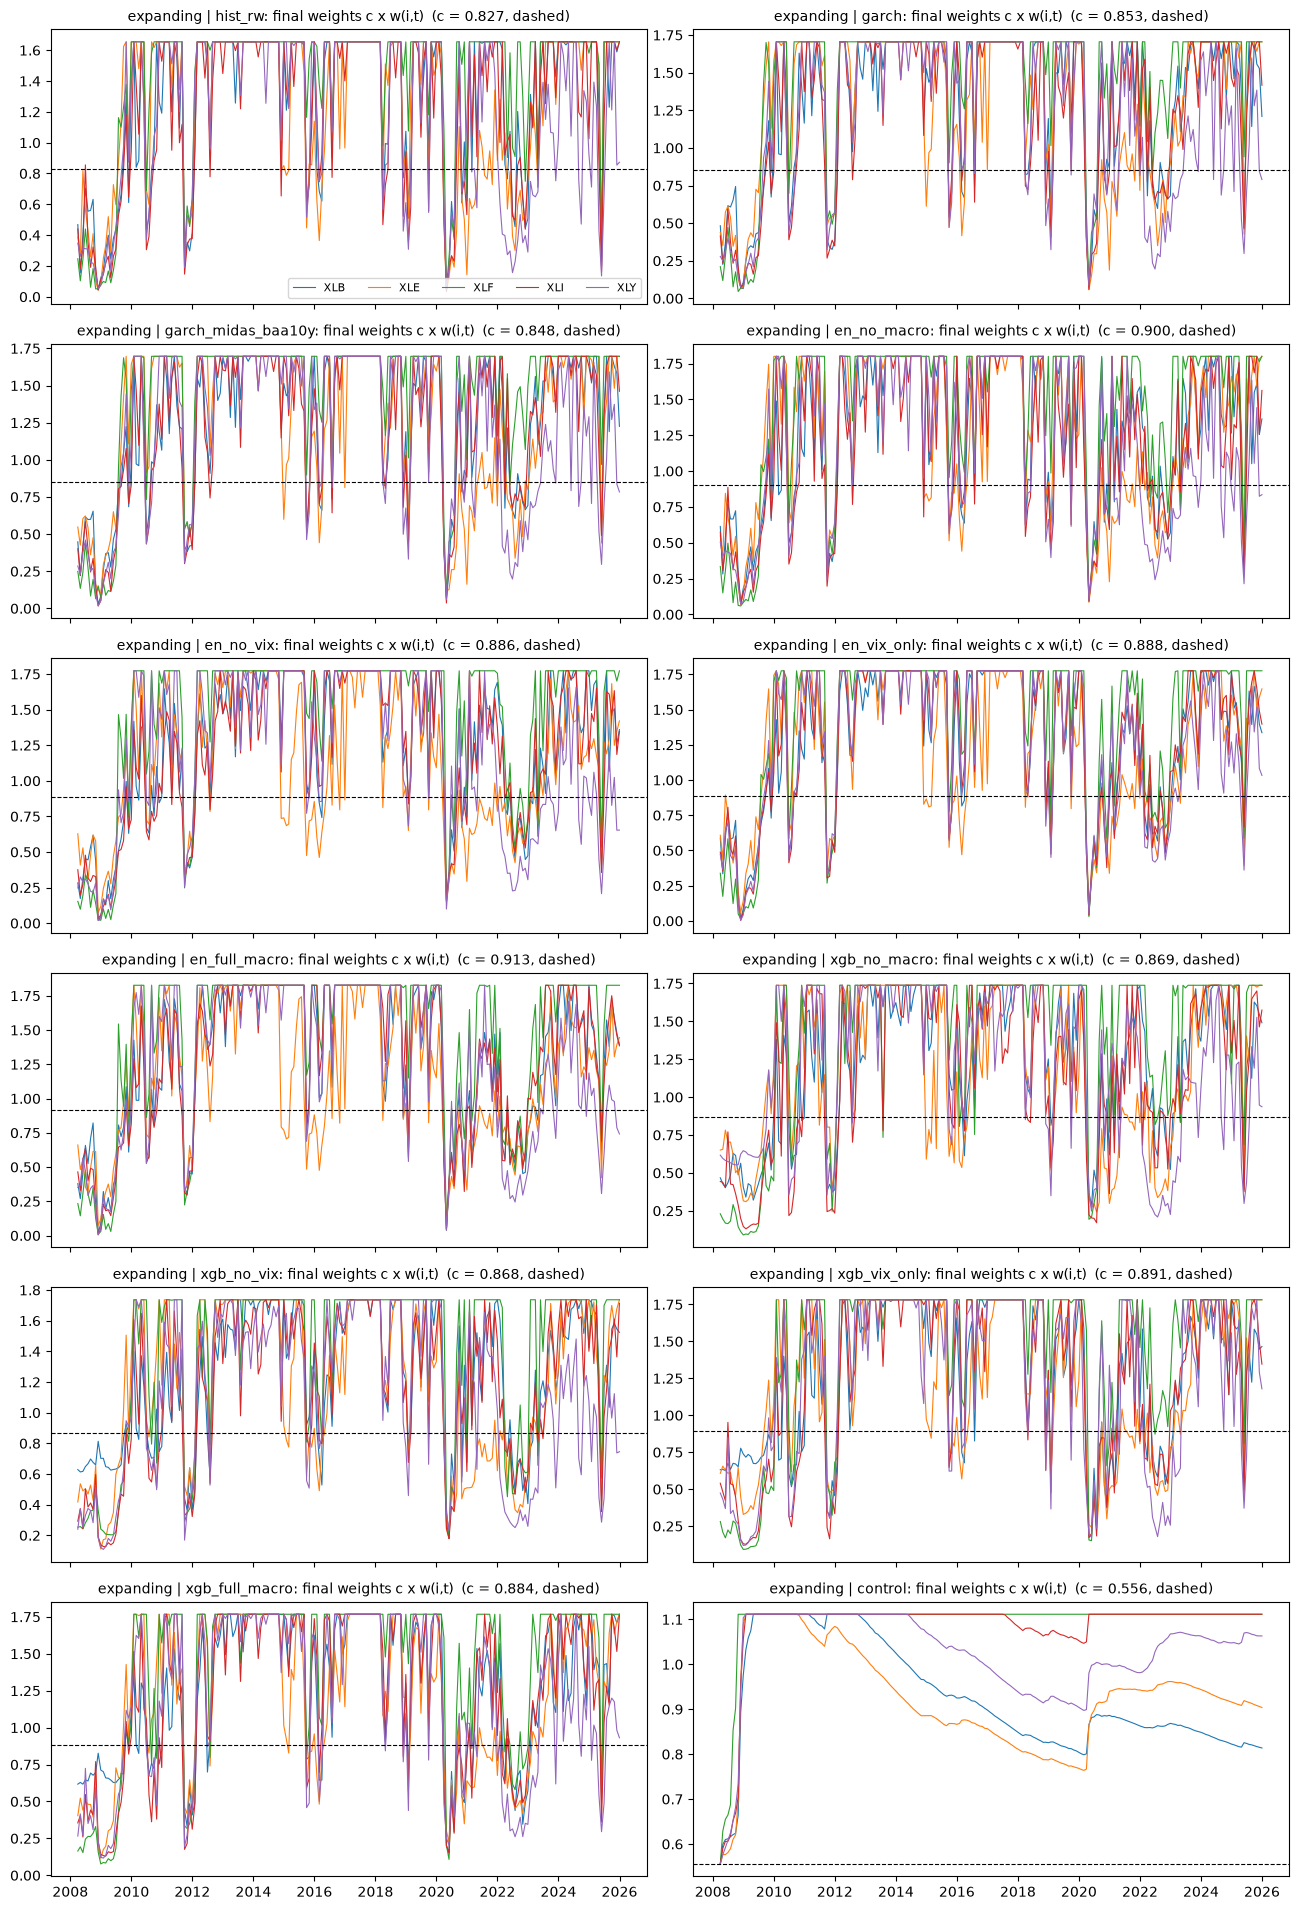

In [13]:
for spec in SPECS:
    res_spec = portfolios[spec]
    ncols = 2
    nrows = int(np.ceil(len(res_spec) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.2 * nrows), sharex=True, squeeze=False)
    for ax, (m, res) in zip(axes.flat, res_spec.items()):
        for t in TICKERS:
            ax.plot(res["weights_final"].index, res["weights_final"][t], linewidth=0.8, label=t)
        ax.axhline(res["c"], color="black", linestyle="--", linewidth=0.8)
        ax.set_title(f"{spec} | {m}: final weights c x w(i,t)  (c = {res['c']:.3f}, dashed)",
                     fontsize=10)
    for ax in axes.flat[len(res_spec):]:
        ax.set_visible(False)
    axes.flat[0].legend(ncol=5, fontsize=8)
    fig.tight_layout()
    plt.show()

## Save the portfolios

Written to `results/portfolios/` and read by notebooks 02 and 03:

- `fixed/` and `expanding/`: `returns.csv` (BH and each managed bucket, wide), `positions.csv` and
  `weights.csv` (per-ETF positions and base weights, long), `c.csv` and `sigma2_bar.csv`.
  `expanding/` also holds the control, under the model name `control`;
- `xret.csv`: monthly excess returns of each ETF, shared by both specifications;
- `weight_diagnostics.csv`: the weight diagnostics above;
- `run_info.json`: the settings of this run (models, pairs, window), so 02 and 03 use the same.

The last check reads the files back and confirms they reproduce the portfolios built here.

In [14]:
for spec in SPECS:
    save_portfolios(portfolios[spec], spec, xret_oos, sigma2_bar[spec])
weight_diag.to_csv(PORTFOLIO_DIR / "weight_diagnostics.csv")

run_info = {
    "selected": available,
    "variants": VARIANTS,
    "benchmark": BENCHMARK,
    "pairs": pairs.reset_index().to_dict(orient="records"),
    "skipped_pairs": skipped.reset_index().to_dict(orient="records"),
    "specs": SPECS,
    "main_spec": MAIN_SPEC,
    "forecast_col": FORECAST_COL,
    "k_cap": K_CAP,
    "train_window": [f"{train_idx.min():%Y-%m}", f"{train_idx.max():%Y-%m}"],
    "oos_window": [f"{oos_idx.min():%Y-%m}", f"{oos_idx.max():%Y-%m}"],
    "tickers": TICKERS,
}
(PORTFOLIO_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2))

for spec in SPECS:
    loaded, _ = load_portfolios(spec)
    assert set(loaded) == set(portfolios[spec])
    for m, res in portfolios[spec].items():
        assert np.allclose(loaded[m]["managed"], res["managed"])
        assert np.allclose(loaded[m]["weights_base"], res["weights_base"])
print("Saved to", PORTFOLIO_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\models\portfolio_construction\results\portfolios
